In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.manifold import TSNE
from hdbscan import HDBSCAN
import seaborn as sns

In [1]:
clust, run = 'gspy', 'O3b'
filterr = True

base = "/home/esanches/Projetos/tSNE/Virgo"
teste = "/home/esanches/Projetos/tSNE/Virgo/zrepository/" + clust + "/" + run

suffix = "_filtered" if filterr else "_"

In [2]:
vecs_path = teste + "/" + "vecs" + suffix + ".npy"
labs_path = teste + "/" + "labs" + suffix + ".npy"
GPSs_path = teste + "/" + "GPSs" + suffix + ".npy"

In [3]:
vecs_path

'/home/esanches/Projetos/tSNE/Virgo/zrepository/gspy/O3b/vecs_filtered.npy'

## tSNE plots for O3b

In [21]:
perp = 100
dt = 2

In [24]:
final_vecs = np.load(vecs_path)
final_labs = np.load(labs_path)

le = LabelEncoder()
labels = le.fit_transform(final_labs.ravel())

final_GPS = np.load(GPSs_path)

tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=42)
proj = tsne.fit_transform(final_vecs)

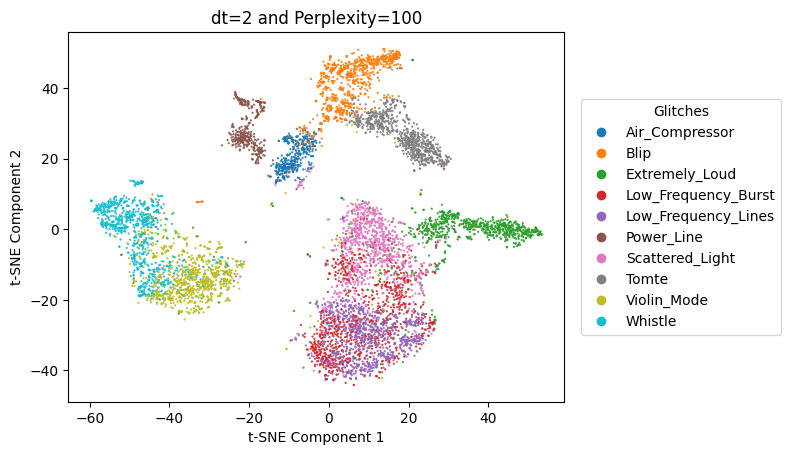

In [25]:
sc = plt.scatter(proj[:, 0], proj[:, 1], s=0.3, c=labels, cmap="tab10")
plt.title(f"dt={dt} and Perplexity={perp}", fontsize=12)
plt.xlabel("t-SNE Component 1", fontsize=10)
plt.ylabel("t-SNE Component 2", fontsize=10)

plt.legend(handles=sc.legend_elements()[0], labels=list(le.classes_), 
          title="Glitches", loc='center left', bbox_to_anchor=(1.02, 0.5))

plt.show()

### Analysis by month

In [26]:
o3b_intervals = {
    'Nov': (1256655618, 1259247618),
    'Dec': (1259247618, 1261926018),
    'Jan': (1261926018, 1264604418),
    'Feb': (1264604418, 1267109218),
    'Mar': (1267109218, 1269734418)
}

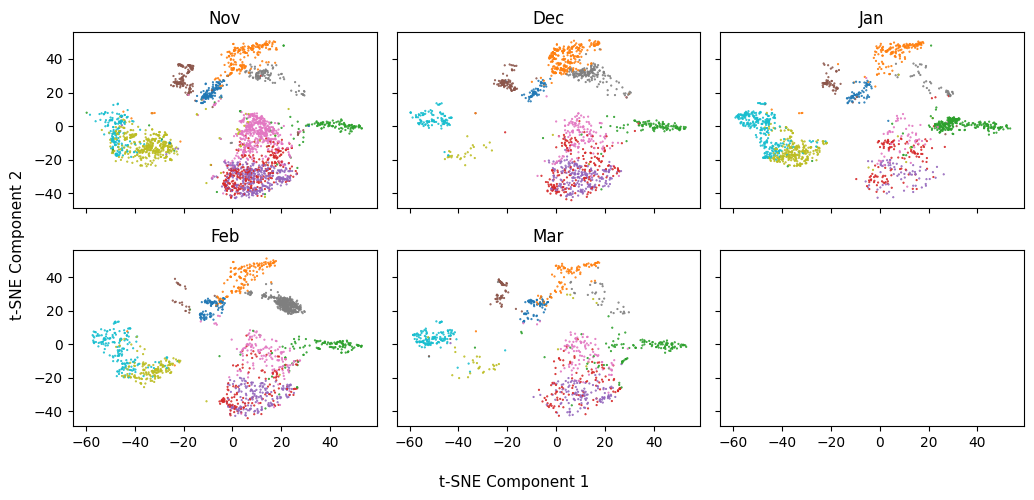

In [27]:
x_axis = int(np.ceil(len(o3b_intervals)/2))

fig, axs = plt.subplots(2, x_axis, figsize=(3.5*x_axis, 5), sharex=True, sharey=True)
axs = axs.flatten()

final_GPSs = np.load(GPSs_path)

for i, (m, (t_start, t_end)) in enumerate(o3b_intervals.items()):

    mask = ((final_GPSs >= t_start) & (final_GPSs <= t_end))

    data_dict = {
        'tsne_x': proj[mask, 0],
        'tsne_y': proj[mask, 1],
        'labels': final_labs[mask]
    }

    labels = le.fit_transform(data_dict['labels'].ravel())
    ax = axs[i]
    
    ax.scatter(data_dict['tsne_x'], data_dict['tsne_y'], s=0.3, c=labels, cmap="tab10")
    ax.set_title(f"{m}", fontsize=12)
    
    fig.supxlabel("t-SNE Component 1", fontsize=11)
    fig.supylabel("t-SNE Component 2", fontsize=11)

plt.tight_layout()
plt.show()

### HDBSCAN* for O3b

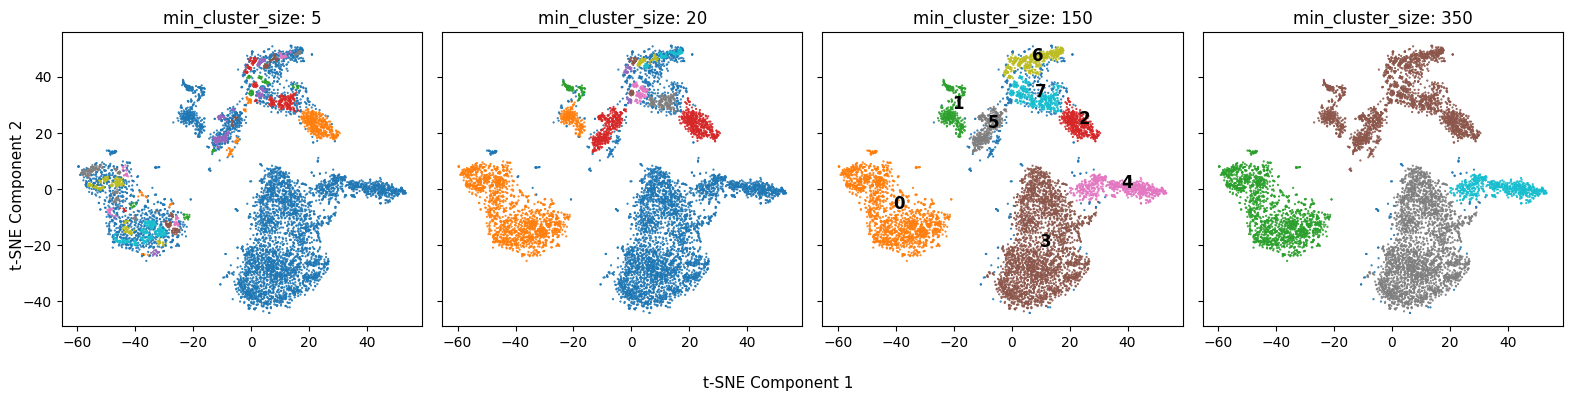

In [34]:
sizes = [5, 20, 150, 350]

fig, axs = plt.subplots(1, len(sizes), figsize=(4*len(sizes), 4), sharex=True, sharey=True)

for i, s in enumerate(sizes):

    hdbscan_labels = HDBSCAN(min_cluster_size=s, min_samples=10, gen_min_span_tree=True).fit_predict(proj)
    unique_labels = np.unique(hdbscan_labels)

    ax = axs[i]
    
    ax.scatter(proj[:, 0], proj[:, 1], s=0.3, c=hdbscan_labels, cmap="tab10")
    ax.set_title(f"min_cluster_size: {s}", fontsize=12)

    if s == 150:
        valid_clusters = [lbl for lbl in unique_labels if lbl > -1]
    
        for lbl in valid_clusters:
            proj_cluster = proj[hdbscan_labels == lbl]

            centroide_x = np.mean(proj_cluster[:, 0])
            centroide_y = np.mean(proj_cluster[:, 1])
            
            ax.text(centroide_x, centroide_y, str(lbl), fontsize=12, fontweight='bold', color='black')

fig.supxlabel("t-SNE Component 1", fontsize=11)
fig.supylabel("t-SNE Component 2", fontsize=11)

plt.tight_layout()
plt.show()

### Correspondence matrix

In [37]:
hdbscan_labels = HDBSCAN(min_cluster_size=150, min_samples=10).fit_predict(proj)

df_compare = pd.DataFrame({'GravitySpy': final_labs, 'HDBSCAN': hdbscan_labels})
mask = (df_compare['HDBSCAN'] != -1)
df_compare_off_noise = df_compare[mask]

matriz_normalizada = pd.crosstab(df_compare_off_noise['GravitySpy'], df_compare_off_noise['HDBSCAN'], normalize='index') * 100

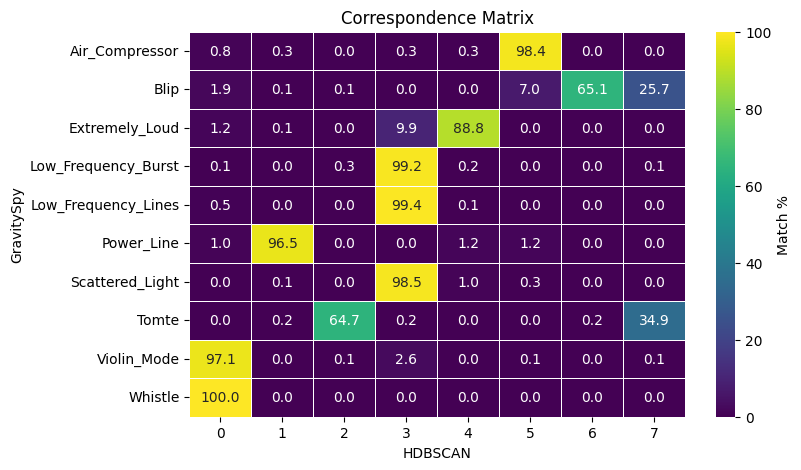

In [41]:
plt.figure(figsize=(8, 5))

sns.heatmap(matriz_normalizada, annot=True, cmap='viridis', fmt='.1f', linewidths=0.5, cbar_kws={'label': 'Match %'})

plt.title('Correspondence Matrix', fontsize=12)

plt.show()

### read the data

Read and apply filters to triggers
  
* To see the lenght, in CMD use: **wc -l arquivename.csv**
* To see the columns, in CMD use: **head -n 1 arquivename.csv**

In [3]:
tperc, gperc = 0.7, 1.0
trigg_size, glit_size = 359385802, 187770

trigcols = ['time', 'frequency', 'snr']
glitcols = ['GPStime', 'centralFreq', 'snr', 'label', 'confidence']

ntrig, nglit = int(trigg_size*tperc), int(glit_size*gperc)

filter1000 = True

The following we will performs a random and filtered read of a large CSV file to save memory

In [4]:
gdchar_source = '/home/esanches/Projetos/tSNE/Virgo/'

In [5]:
np.random.seed(42)
skip_logic = lambda i: i > 0 and np.random.random() > tperc
trigg = pd.read_csv(gdchar_source + 'triggers_total.csv', skiprows=skip_logic, usecols=trigcols)
trigg = trigg.sort_values('time').reset_index(drop=True)

unclustered = trigg.copy()

In [6]:
unclustered.to_csv('/home/esanches/Projetos/tSNE/Virgo/zrepository/' + run + '/unclustered.csv')

and for glitches

In [7]:
glit = pd.read_csv(gdchar_source + 'gspy' + run + '.csv', usecols=glitcols)

glit = glit.drop(glit[glit['label'].isin(['None_of_the_Above', 'No_Glitch'])].index)
glit = glit[glit['confidence'] >= 0.9]

top10 = glit['label'].value_counts().head(10).index
glit = glit[glit['label'].isin(top10)].copy()

glit = glit.sort_values(by=[glitcols[0]]).reset_index(drop=True)

if filter1000 == True:
    limited_glit = glit.groupby('label', group_keys=False).apply(lambda x: x.sample(n=min(len(x), 1000), random_state=42))

    limited_glit = limited_glit.sort_values(by=[glitcols[0]]).reset_index(drop=True)
    clustered = limited_glit.copy()
else:
    clustered = glit.copy()

In [8]:
clustered.to_csv('/home/esanches/Projetos/tSNE/Virgo/zrepository/' + run + '/clustered.csv')

### glitchgram creation

Select the **dt** window around the glitch a

In [59]:
savepath = '/home/esanches/Projetos/tSNE/Virgo/zrepository/' + run + '/'
arq_name = 'gspy'
dt = 2

In [60]:
vecs, labs, GPSs = gf.glitch_to_glitchgram(unclustered, clustered, savepath, arq_name, deltat=dt, fmin=3, fmax=8192, tbins=41, fbins=30)

### tSNE plots

In [189]:
readpath = '/home/esanches/Projetos/tSNE/Virgo/zrepository/' + run + '/'
final_vecs = np.load(readpath + 'vecs_gspy_dt2.npy')
final_labs = np.load(readpath + 'labs_gspy_dt2.npy')

tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=100, learning_rate=200, 
            max_iter=1000, metric="euclidean", random_state=0)
proj = tsne.fit_transform(final_vecs)

proj_df = pd.DataFrame(proj, columns=['x axis', 'y axis'])
labs_df = pd.DataFrame(final_labs, columns=['label'])

cmap = plt.colormaps["tab10"]
le = LabelEncoder()
labels = le.fit_transform(labs_df.values.ravel())

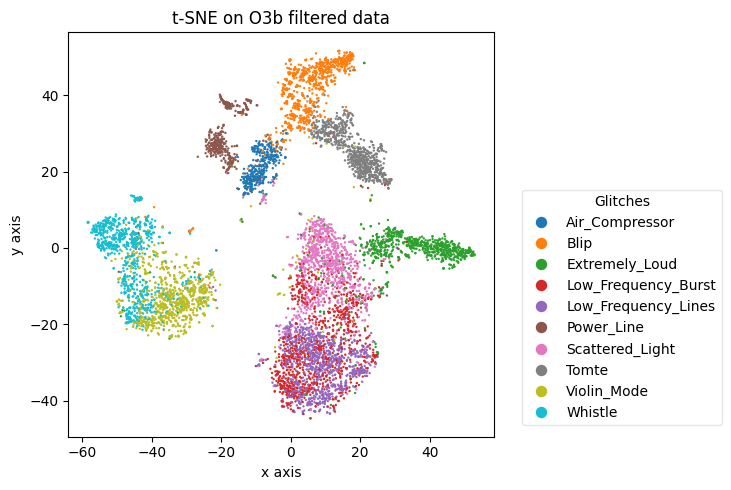

In [198]:
plt.figure(figsize=(8, 5))

sc = plt.scatter(proj_df.values[:,0], proj_df.values[:,1], s=0.5, c=labels, cmap=cmap)
plt.legend(handles=sc.legend_elements()[0], labels=list(le.classes_), title="Glitches", loc='center', framealpha=0.5, markerscale=1.2, bbox_to_anchor=(1.3, 0.32))

plt.title(f't-SNE on O3b filtered data')
plt.xlabel('x axis')
plt.ylabel('y axis')
plt.tight_layout()
plt.show()

In [ ]:
pxs = [10, 30, 90, 270, 810]
fig, axs = plt.subplots(1, len(pxs), figsize=(4*len(pxs), 3))

for i, p in enumerate(pxs):
    
    tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=p, learning_rate=200, 
            max_iter=1000, metric="euclidean", random_state=0)

    proj = tsne.fit_transform(final_vecs)
    proj_df = pd.DataFrame(proj, columns=['x axis', 'y axis'])
    labs_df = pd.DataFrame(final_labs, columns=['label'])

    axs[i].set_title(f'perplexity: {p}')
    axs[i].scatter(proj_df.values[:,0], proj_df.values[:,1], s=0.2, c=labels, cmap=cmap)

plt.show()

### Analysis by month

In [52]:
readpath = '/home/esanches/Projetos/tSNE/Virgo/zrepository/' + run + '/'

In [54]:
final_vecs = np.load(readpath + 'vecs_gspy_dt2.npy')
final_labs = np.load(readpath + 'labs_gspy_dt2.npy')
final_GPSs = np.load(readpath + 'GPSs_gspy_dt2.npy')

In [55]:
tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=100, learning_rate=200, 
            max_iter=1000, metric="euclidean", random_state=0)

proj = tsne.fit_transform(final_vecs)
proj_df = pd.DataFrame(proj, columns=['x axis', 'y axis'])

In [61]:
labs = pd.DataFrame(final_labs).rename(columns={0 : 'vecs'})
GPSs = pd.DataFrame(final_GPSs).rename(columns={0 : 'GPSs'})

o3b_intervals = {
    'Nov': (1256655618, 1259247618),
    'Dec': (1259247618, 1261926018),
    'Jan': (1261926018, 1264604418),
    'Feb': (1264604418, 1267109218),  # 2020 foi ano bissexto (fevereiro com 29 dias)
    'Mar': (1267109218, 1269734418)   # Término oficial em 27 de Março de 2020
}

gps_1d = np.array(GPSs).ravel()
labs = np.array(labs).ravel()

In [62]:
projs_count = []

for m, (t_start, t_end) in o3b_intervals.items():

    mask = (gps_1d >= t_start) & (gps_1d < t_end)

    globals()[f"proj_{m.lower()}"] = pd.DataFrame({
    'tsne_1': proj_df.iloc[mask, 0],
    'tsne_2': proj_df.iloc[mask, 1],
    'label': labs[mask],
    'GPStime': gps_1d[mask]
    })

    projs_count.append(mask.sum())

    print(f"proj_{m.lower()} ({mask.sum()} projections)")

proj_nov (2479 projections)
proj_dec (1431 projections)
proj_jan (1457 projections)
proj_feb (1586 projections)
proj_mar (950 projections)


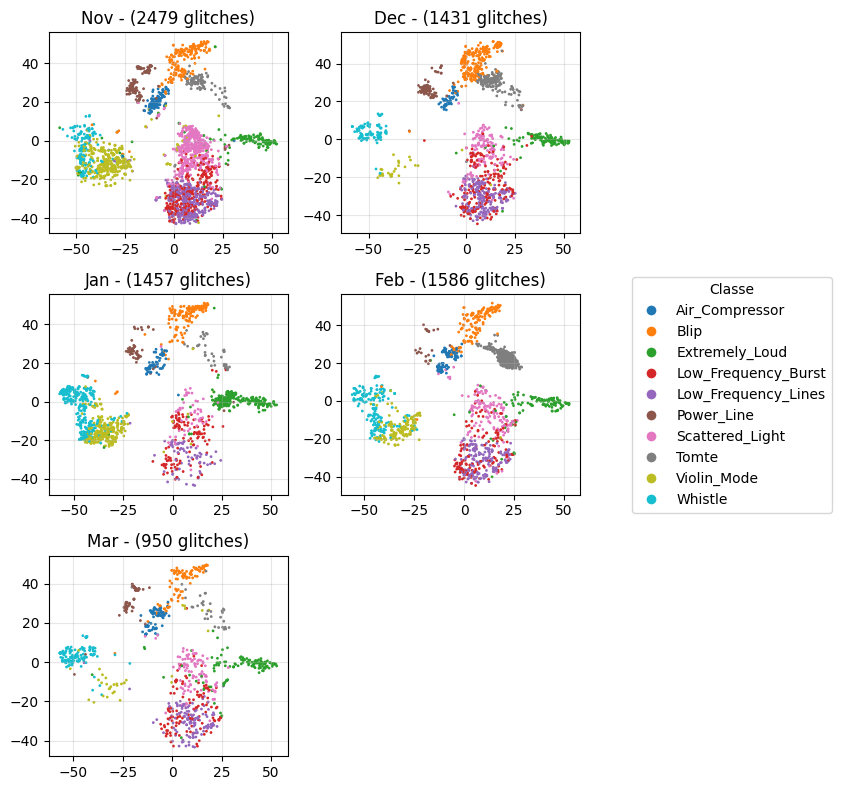

In [66]:
fig, axs = plt.subplots(3, 2, figsize=(6, 8))
axs = axs.ravel()

axs[-1].set_visible(False)
months = o3b_intervals.keys()

le = LabelEncoder()
le.fit(labs)
cmap = plt.get_cmap("tab10")

for i, m in enumerate(months):

    proj = globals()[f"proj_{m.lower()}"]
    
    cores = le.transform(proj['label'])
    
    axs[i].scatter(proj["tsne_1"], proj["tsne_2"], c=cores, cmap=cmap, s=1)
    axs[i].set_title(f'{m} - ({projs_count[i]} glitches)')
    axs[i].grid(True, alpha=0.3)


# legend
handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=cmap(i), markersize=8, label=label) for i, label in enumerate(le.classes_)]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.05, 0.5), title="Classe")

fig.tight_layout()
plt.show()

### HDBSCAN*

Matrix creation

In [128]:
# Read the data
readpath = '/home/esanches/Projetos/tSNE/Virgo/zrepository/' + run + '/'
final_vecs = np.load(readpath + 'vecs_gspy_dt2.npy')
final_labs = np.load(readpath + 'labs_gspy_dt2.npy')

# Apply tSNE
tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=100, learning_rate=200, 
            max_iter=1000, metric="euclidean", random_state=0)
proj = tsne.fit_transform(final_vecs)

# Transform in dataFrame
proj_df = pd.DataFrame(proj, columns=['x axis', 'y axis'])
labs_df = pd.DataFrame(final_labs, columns=['label'])

In [129]:
X_tsne = proj_df[["x axis", "y axis"]].values
y_labels = labs_df.values

In [130]:
X_tsne

array([[-15.383382 ,  15.584115 ],
       [ 20.367378 ,   0.3925794],
       [-45.25853  ,  -3.5575013],
       ...,
       [-28.950485 ,   3.7038586],
       [ -8.507651 ,  19.273796 ],
       [ 36.430637 ,   1.0452551]], shape=(7903, 2), dtype=float32)

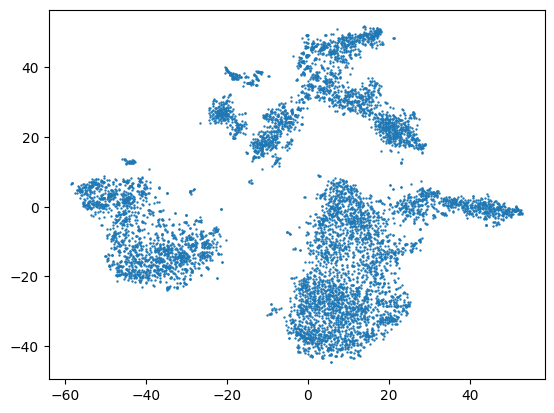

In [131]:
plt.scatter(*X_tsne.T, s=0.5)

Correlation matrix for min_cluster_size = 100

See the glitchgrams

In [183]:
clustered_reset = clustered.reset_index(drop=True)

df_tsne = pd.DataFrame(proj, columns=['x axis', 'y axis'])
df_tsne['GPStime'] = clustered_reset['GPStime']
df_tsne['label'] = clustered_reset['label']

In [184]:
def obter_matriz_glitchgrama(unclustered, target_gps, deltat=2, fmin=3, fmax=8192, tbins=41, fbins=30):
    """
    Retorna a matriz A (SNR) individual para um determinado GPS.
    """
    tmin = target_gps - deltat / 2
    tmax = target_gps + deltat / 2

    mask_tempo = (unclustered["time"] >= tmin) & (unclustered["time"] <= tmax)
    subset_dados = unclustered[mask_tempo]

    times = subset_dados["time"].values - target_gps
    freqs = subset_dados["frequency"].values
    snrs = subset_dados["snr"].values

    time_edges = np.linspace(-deltat / 2, deltat / 2, tbins + 1)
    freq_edges = np.logspace(np.log10(fmin), np.log10(fmax), fbins + 1)

    A = np.zeros((fbins, tbins), dtype=float)
    if len(times) > 0:
        t_idx = np.digitize(times, time_edges) - 1
        f_idx = np.digitize(freqs, freq_edges) - 1
        for ti, fi, si in zip(t_idx, f_idx, snrs):
            if 0 <= ti < tbins and 0 <= fi < fbins:
                if si > A[fi, ti]:
                    A[fi, ti] = si
    return A

Círculo em (-20, 25): Encontrados 53 glitches dentro do raio 2.0
Classes presentes neste círculo:
label
Power_Line             10
Blip                    9
Low_Frequency_Burst     9
Scattered_Light         7
Violin_Mode             6
Whistle                 5
Low_Frequency_Lines     3
Tomte                   2
Air_Compressor          1
Extremely_Loud          1
Name: count, dtype: int64
--------------------------------------------------
Círculo em (-15, 35): Encontrados 23 glitches dentro do raio 2.0
Classes presentes neste círculo:
label
Low_Frequency_Lines    7
Low_Frequency_Burst    4
Violin_Mode            3
Power_Line             2
Scattered_Light        2
Air_Compressor         2
Whistle                1
Tomte                  1
Blip                   1
Name: count, dtype: int64
--------------------------------------------------


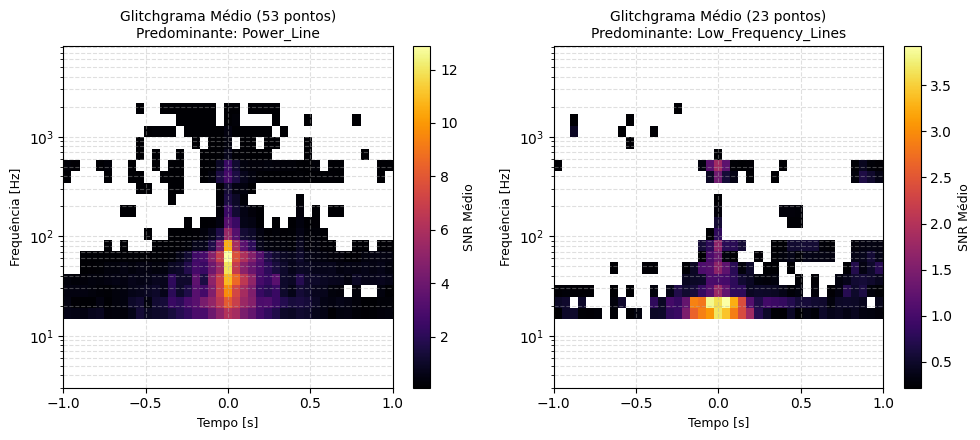

In [185]:
xs, ys = [-20, -15], [25, 35]
raio_selecao = 2.0

deltat = 2
fmin, fmax = 3, 8192
tbins, fbins = 41, 30

fig, axs = plt.subplots(1, len(xs), figsize=(len(xs) * 5, 4.5))
axs = np.atleast_1d(axs)

for idx, (cx, cy) in enumerate(zip(xs, ys)):
    distancias = np.sqrt((df_tsne['x axis'] - cx)**2 + (df_tsne['y axis'] - cy)**2)
    
    pontos_no_circulo = df_tsne[distancias <= raio_selecao]
    
    qtd_pontos = len(pontos_no_circulo)
    print(f"Círculo em ({cx}, {cy}): Encontrados {qtd_pontos} glitches dentro do raio {raio_selecao}")
    
    if qtd_pontos == 0:
        axs[idx].text(0.5, 0.5, "Nenhum ponto\nno raio selecionado", ha='center', va='center')
        axs[idx].set_title(f"Centro: ({cx}, {cy})")
        continue

    print("Classes presentes neste círculo:")
    print(pontos_no_circulo['label'].value_counts())
    print("-" * 50)
    
    matrizes_acumuladas = []
    for gps_ponto in pontos_no_circulo['GPStime']:
        A_ind = obter_matriz_glitchgrama(unclustered, gps_ponto, deltat, fmin, fmax, tbins, fbins)
        matrizes_acumuladas.append(A_ind)
        
    matrizes_np = np.array(matrizes_acumuladas)
    
    A_media = np.mean(matrizes_np, axis=0)
    
    A_plot = np.where(A_media == 0, np.nan, A_media)

    time_edges = np.linspace(-deltat / 2, deltat / 2, tbins + 1)
    freq_edges = np.logspace(np.log10(fmin), np.log10(fmax), fbins + 1)
    X_mesh, Y_mesh = np.meshgrid(time_edges, freq_edges)

    mesh = axs[idx].pcolormesh(X_mesh, Y_mesh, A_plot, cmap="inferno", shading="flat")

    axs[idx].set_yscale("log")
    axs[idx].set_ylim(fmin, fmax)
    axs[idx].set_xlim(-deltat / 2, deltat / 2)

    cbar = plt.colorbar(mesh, ax=axs[idx])
    cbar.set_label("SNR Médio", fontsize=9)

    classe_predominante = pontos_no_circulo['label'].mode()[0]
    axs[idx].set_title(f"Glitchgrama Médio ({qtd_pontos} pontos)\nPredominante: {classe_predominante}", fontsize=10)
    axs[idx].set_xlabel("Tempo [s]", fontsize=9)
    axs[idx].set_ylabel("Frequência [Hz]", fontsize=9)
    axs[idx].grid(True, which="both", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Círculo em (-20, 25): Encontrados 53 glitches
Classes reais neste círculo:
label
Power_Line    53
Name: count, dtype: int64
--------------------------------------------------
Círculo em (-15, 35): Encontrados 23 glitches
Classes reais neste círculo:
label
Power_Line    22
Blip           1
Name: count, dtype: int64
--------------------------------------------------


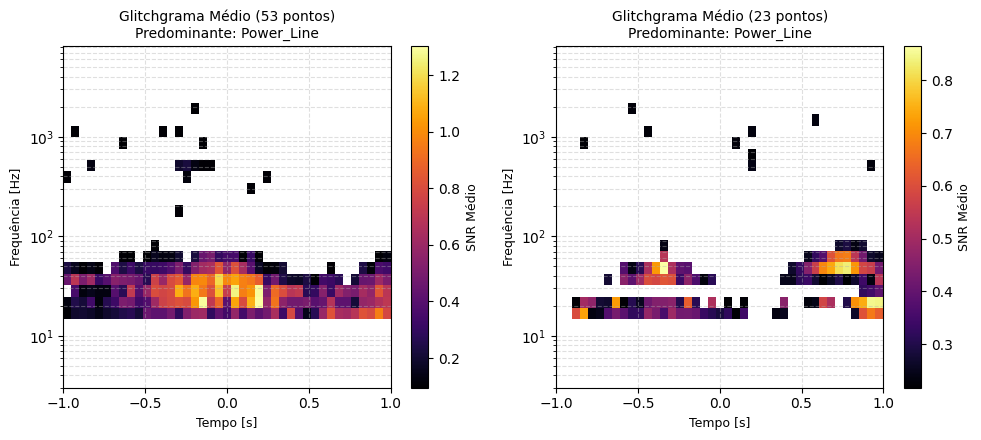

In [186]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# ==============================================================================
# 1. CARREGAMENTO E ALINHAMENTO ORIGINAL (100% SEGURO)
# ==============================================================================

readpath = '/home/esanches/Projetos/tSNE/Virgo/zrepository/' + run + '/'

# Carrega os dados originais que possuem exatamente a mesma ordenação do t-SNE (proj)
final_labs = np.load(readpath + 'labs_gspy_dt2.npy')
final_gps = np.load(readpath + 'GPSs_gspy_dt2.npy')

# Monta o DataFrame usando única e exclusivamente os dados originais alinhados com o t-SNE
df_tsne = pd.DataFrame(proj, columns=['x axis', 'y axis'])
df_tsne['GPStime'] = final_gps
df_tsne['label'] = final_labs


# ==============================================================================
# 2. DEFINIÇÃO DA FUNÇÃO DO GLITCHGRAMA INDIVIDUAL
# ==============================================================================

def obter_matriz_glitchgrama(unclustered, target_gps, deltat=2, fmin=3, fmax=8192, tbins=41, fbins=30):
    tmin = target_gps - deltat / 2
    tmax = target_gps + deltat / 2

    # Busca segura por máscara booleana no unclustered
    mask_tempo = (unclustered["time"] >= tmin) & (unclustered["time"] <= tmax)
    subset_dados = unclustered[mask_tempo]

    times = subset_dados["time"].values - target_gps
    freqs = subset_dados["frequency"].values
    snrs = subset_dados["snr"].values

    time_edges = np.linspace(-deltat / 2, deltat / 2, tbins + 1)
    freq_edges = np.logspace(np.log10(fmin), np.log10(fmax), fbins + 1)

    A = np.zeros((fbins, tbins), dtype=float)
    if len(times) > 0:
        t_idx = np.digitize(times, time_edges) - 1
        f_idx = np.digitize(freqs, freq_edges) - 1
        for ti, fi, si in zip(t_idx, f_idx, snrs):
            if 0 <= ti < tbins and 0 <= fi < fbins:
                if si > A[fi, ti]:
                    A[fi, ti] = si
    return A


# ==============================================================================
# 3. SELEÇÃO DOS PONTOS NO t-SNE E PLOTAGEM DO GLITCHGRAMA MÉDIO REAL
# ==============================================================================

# Seus pontos de teste no t-SNE
xs, ys = [-20, -15], [25, 35]
raio_selecao = 2.0

deltat = 2
fmin, fmax = 3, 8192
tbins, fbins = 41, 30

fig, axs = plt.subplots(1, len(xs), figsize=(len(xs) * 5, 4.5))
axs = np.atleast_1d(axs)

for idx, (cx, cy) in enumerate(zip(xs, ys)):
    # Calcula a distância euclidiana correta usando as coordenadas reais do t-SNE (df_tsne)
    distancias = np.sqrt((df_tsne['x axis'] - cx)**2 + (df_tsne['y axis'] - cy)**2)
    pontos_no_circulo = df_tsne[distancias <= raio_selecao]
    
    qtd_pontos = len(pontos_no_circulo)
    print(f"Círculo em ({cx}, {cy}): Encontrados {qtd_pontos} glitches")
    
    if qtd_pontos == 0:
        axs[idx].text(0.5, 0.5, "Nenhum ponto encontrado\nno raio selecionado", ha='center', va='center')
        axs[idx].set_title(f"Centro: ({cx}, {cy})")
        continue

    print("Classes reais neste círculo:")
    print(pontos_no_circulo['label'].value_counts())
    print("-" * 50)

    # Coleta as matrizes corretas de SNR
    matrizes_acumuladas = []
    for gps_ponto in pontos_no_circulo['GPStime']:
        A_ind = obter_matriz_glitchgrama(unclustered, gps_ponto, deltat, fmin, fmax, tbins, fbins)
        matrizes_acumuladas.append(A_ind)
        
    matrizes_np = np.array(matrizes_acumuladas)
    A_media = np.mean(matrizes_np, axis=0)
    A_plot = np.where(A_media == 0, np.nan, A_media)

    # Plotagem
    time_edges = np.linspace(-deltat / 2, deltat / 2, tbins + 1)
    freq_edges = np.logspace(np.log10(fmin), np.log10(fmax), fbins + 1)
    X_mesh, Y_mesh = np.meshgrid(time_edges, freq_edges)

    mesh = axs[idx].pcolormesh(X_mesh, Y_mesh, A_plot, cmap="inferno", shading="flat")

    axs[idx].set_yscale("log")
    axs[idx].set_ylim(fmin, fmax)
    axs[idx].set_xlim(-deltat / 2, deltat / 2)

    cbar = plt.colorbar(mesh, ax=axs[idx])
    cbar.set_label("SNR Médio", fontsize=9)

    # Pega o label correto do array original
    classe_predominante = pontos_no_circulo['label'].mode()[0]
    axs[idx].set_title(f"Glitchgrama Médio ({qtd_pontos} pontos)\nPredominante: {classe_predominante}", fontsize=10)
    axs[idx].set_xlabel("Tempo [s]", fontsize=9)
    axs[idx].set_ylabel("Frequência [Hz]", fontsize=9)
    axs[idx].grid(True, which="both", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [150]:
xs, ys = [-20, -15], [25, 35]

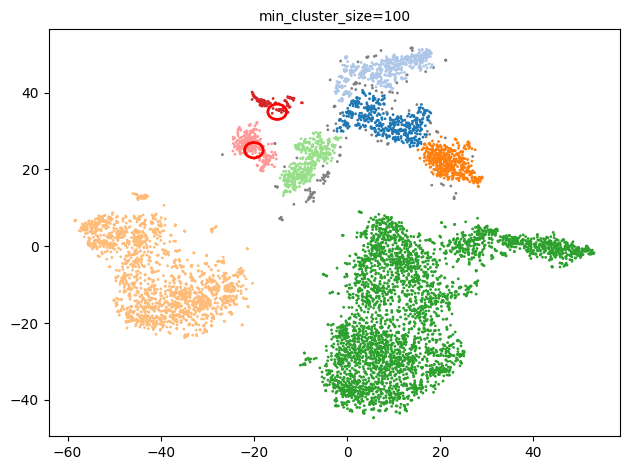

In [151]:
size = 100

hdbscan_labels = HDBSCAN(min_cluster_size=size, min_samples=5, gen_min_span_tree=True).fit_predict(X_tsne)
pal = colors(hdbscan_labels)

plt.scatter(*X_tsne.T, c=[pal[x] if x >= 0 else (0.5, 0.5, 0.5) for x in hdbscan_labels], s=1)
plt.title(f'min_cluster_size={size}', fontsize=10)

for x, y in zip(xs, ys):
    circulo = plt.Circle((x, y), 2, fill=False, edgecolor="red", lw=2)
    plt.gca().add_patch(circulo)

plt.tight_layout()
plt.show()

In [163]:
# ==========================================
# PASSO 1: Garanta um DataFrame de t-SNE perfeitamente alinhado
# ==========================================
# (Rode isso antes de plotar os círculos vermelhos)

# Crie o DataFrame do t-SNE com índice sequencial padrão (0, 1, 2...)
df_tsne = pd.DataFrame(X_tsne, columns=['x axis', 'y axis'])

# Resete o índice do seu DataFrame 'clustered' para garantir que as posições batam 100%
clustered_reset = clustered.reset_index(drop=True)

# Adicione as colunas necessárias direto no DataFrame do t-SNE
df_tsne['GPStime'] = clustered_reset['GPStime']
df_tsne['label'] = clustered_reset['label']


# ==========================================
# PASSO 2: Buscar os pontos usando o df_tsne unificado
# ==========================================
xs, ys = [-20, -15], [25, 35]
GPS_points = []

for x, y in zip(xs, ys):
    ponto_alvo = np.array([x, y])
    
    # Calcula a distância usando as colunas do próprio DataFrame do t-SNE
    distancias_ao_quadrado = (df_tsne['x axis'] - x)**2 + (df_tsne['y axis'] - y)**2
    i_proximo = distancias_ao_quadrado.idxmin() # Pega o Index exato do Pandas

    info_ponto = df_tsne.loc[i_proximo]
    
    print(f"Ponto mais próximo encontrado no índice {i_proximo}:")
    print(f"Label: {info_ponto['label']} | GPS: {info_ponto['GPStime']}")
    print("-" * 40)
    
    GPS_points.append(info_ponto['GPStime'])

Ponto mais próximo encontrado no índice 1706:
Label: Violin_Mode | GPS: 1258208231.555
----------------------------------------
Ponto mais próximo encontrado no índice 920:
Label: Low_Frequency_Lines | GPS: 1257682849.469
----------------------------------------


In [164]:
def plot_single_glitchgram_subplot(ax, unclustered, clustered, target_gps, deltat, fmin=3, fmax=8192, tbins=41, fbins=30):

    idx_closest = (clustered["GPStime"] - target_gps).abs().idxmin()
    row = clustered_reset[clustered_reset["GPStime"] == target_gps].iloc[0]
    t_center = row["GPStime"]
    label_glitch = row["label"]

    times_all = unclustered["time"].values
    freqs_all = unclustered["frequency"].values
    snrs_all = unclustered["snr"].values

    tmin = t_center - deltat / 2
    tmax = t_center + deltat / 2

    time_edges = np.linspace(-deltat / 2, deltat / 2, tbins + 1)
    freq_edges = np.logspace(np.log10(fmin), np.log10(fmax), fbins + 1)

    i0 = np.searchsorted(times_all, tmin, side="left")
    i1 = np.searchsorted(times_all, tmax, side="right")

    times = times_all[i0:i1] - t_center
    freqs = freqs_all[i0:i1]
    snrs = snrs_all[i0:i1]

    A = np.zeros((fbins, tbins), dtype=float)
    if len(times) > 0:
        t_idx = np.digitize(times, time_edges) - 1
        f_idx = np.digitize(freqs, freq_edges) - 1
        for ti, fi, si in zip(t_idx, f_idx, snrs):
            if 0 <= ti < tbins and 0 <= fi < fbins:
                if si > A[fi, ti]:
                    A[fi, ti] = si

    X_mesh, Y_mesh = np.meshgrid(time_edges, freq_edges)
    A_plot = np.where(A == 0, np.nan, A)

    # ATENÇÃO: Mudamos de plt.pcolormesh para ax.pcolormesh
    mesh = ax.pcolormesh(X_mesh, Y_mesh, A_plot, cmap="inferno", shading="flat")

    ax.set_yscale("log")
    ax.set_ylim(fmin, fmax)
    ax.set_xlim(-deltat / 2, deltat / 2)

    # Adiciona a barra de cores associada a este eixo específico
    cbar = plt.colorbar(mesh, ax=ax)
    cbar.set_label("SNR", fontsize=9)

    ax.set_title(f"GPS: {t_center}\nSpy: {label_glitch}", fontsize=10)
    ax.set_xlabel("Tempo [s]", fontsize=9)
    ax.set_ylabel("Frequência [Hz]", fontsize=9)
    ax.grid(True, which="both", linestyle="--", alpha=0.4)

HDBSCAN for LLS glitches